# First ML Pipeline with AutoML

<!--<badge>--><a href="https://colab.research.google.com/github/kuennethgroup/ml_in_ms_wt26/blob/main/02_ex/first_ml_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a><!--</badge>-->

In this tutorial, we'll use the `pandas` Python library to import a polymer dataset containing information on the tendency to crystallize for 432 polymers. After plotting a histogram of the dataset, we'll use the automated machine learning (AutoML) libraries FLAML and AutoGluon to train ML models. Finally, we'll analyze model performance using parity plots, plotted with matplotlib.

## Overview

We'll explore two popular AutoML frameworks:

#### FLAML (A Fast Library for Automated Machine Learning & Tuning)

FLAML automates the training of machine learning models by automatically searching for high-quality models. It iterates through various machine learning algorithms and hyperparameters to find the best-performing model for your dataset.

#### AutoGluon

AutoGluon is another powerful AutoML framework that automatically trains and tunes multiple models, creating ensembles to achieve state-of-the-art performance with minimal configuration.

In [1]:
# on Colab
# !pip install flaml[automl]

## Step 1: Load and Explore Data

**Tasks:**

1. Use `pandas` to read the polymer dataset from the URL into a DataFrame named `df`.
2. Plot a histogram showing the distribution of property values using 40 bins.

This will help us understand the distribution and range of the target variable we're trying to predict.

,smiles,property,value
0,[*]C[*],Xc,47.80
1,[*]CC([*])C,Xc,44.47
2,[*]CC([*])CC,Xc,34.04
3,[*]CC([*])CCC,Xc,20.01
4,[*]CC([*])CC(C)C,Xc,21.64
...,...,...,...
427,[*]C([*])(F)F,Xc,31.84
428,[*]C/C=C\C[*],Xc,25.58
429,[*]O[Si](C)(C)CCCC(=O)Oc1ccc(C=Nc2ccc(N=Cc3ccc...,Xc,29.05
430,[*]O[Si](C)(C)CCCC(=O)Oc1ccc(C=Nc2ccc(Cc3ccc(N...,Xc,21.74


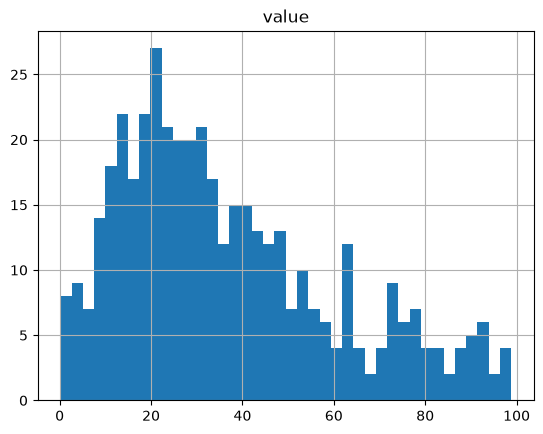

In [2]:
import pandas as pd
import numpy as np

# load and drop fingerprints; will generate them here ourself
df = pd.read_json(
    "https://raw.githubusercontent.com/kuennethgroup/materials_datasets/refs/heads/main/polymer_tendency_to_crystalize/polymers_tend_to_crystalize.json"
).drop(columns=["fingerprint"])

df.hist("value", bins=40)
df

In [3]:
# Add fingerprint vectors column to dataframe
from psmiles import PolymerSmiles as PS

df["fingerprint"] = df["smiles"].apply(lambda x: PS(x).fingerprint())
df

,smiles,property,value,fingerprint
0,[*]C[*],Xc,47.80,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,[*]CC([*])C,Xc,44.47,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,[*]CC([*])CC,Xc,34.04,"[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,[*]CC([*])CCC,Xc,20.01,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,[*]CC([*])CC(C)C,Xc,21.64,"[0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...
427,[*]C([*])(F)F,Xc,31.84,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
428,[*]C/C=C\C[*],Xc,25.58,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
429,[*]O[Si](C)(C)CCCC(=O)Oc1ccc(C=Nc2ccc(N=Cc3ccc...,Xc,29.05,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
430,[*]O[Si](C)(C)CCCC(=O)Oc1ccc(C=Nc2ccc(Cc3ccc(N...,Xc,21.74,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."


In [4]:
# reorder the dataframe for training
# we need fingerprints as input and the tendency to crystallize as output

# vertical stacks lists of fingerprints into a 2D numpy array
# creates a 432 x 2048 numpy array of fingerprints
fingerprints = np.vstack(df["fingerprint"])
display(fingerprints)

# make a dataframe of fingerprints with column names fp_0, fp_1, ..., fp_2047
X_all = pd.DataFrame(fingerprints, columns=[f"fp_{i}" for i in range(fingerprints.shape[1])])

# make a series of floats for the tendency to crystallize
y_all = df["value"].apply(float).to_frame(name="tendency_to_crystallize")

# concatenate the fingerprints and the tendency to crystallize into a single dataframe
# So we have tendency to crystallize as the first column and the fingerprints as the rest of the columns (fp_*)
all_data = pd.concat([y_all, X_all], axis=1)
all_data


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [1, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 1]], shape=(432, 2048))

,tendency_to_crystallize,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,47.80,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,44.47,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,34.04,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,20.01,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,21.64,0,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
427,31.84,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
428,25.58,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
429,29.05,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
430,21.74,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Split the dataset into 80 % training and 20 % test data

In [5]:
from sklearn.model_selection import train_test_split

# split in 20 / 80 train / test split (see #rows in the dataframes)
train_data, test_data = train_test_split(all_data, test_size=0.2, random_state=42)
display(train_data)
display(test_data)


,tendency_to_crystallize,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
132,57.620000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
231,28.370000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31,21.610000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
84,79.990000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
296,0.370000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,29.770000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
106,21.110000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
270,8.900000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
348,12.490000,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


,tendency_to_crystallize,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
424,8.380000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
75,72.530000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
180,53.050000,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
30,16.730000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
392,38.130000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,62.840000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
124,88.390000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
24,12.637895,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17,37.020000,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Step 2: Train Model with FLAML

Now we'll train a regression model using FLAML's AutoML capabilities. FLAML will automatically test different algorithms and hyperparameters to find the best-performing model.

**Evaluation Metric:**

We'll use Mean Squared Error (MSE) to evaluate model performance:

$$\text{Mean Squared Error (MSE)} = \frac{1}{n} \sum_{i=1}^n (Y_i - \hat{Y}_i)^2$$

where:
- $Y_i$ = true value
- $\hat{Y}_i$ = predicted value  
- $n$ = number of samples

Lower MSE values indicate better model performance.

In [7]:
# In case FLAML is not installed, execute
# !pip install -U "flaml[automl]"

from flaml import AutoML

automl_flaml = AutoML()


automl_settings = {
    "task": "regression",  # Classification (e.g., yes, no, maybe) is also possible
    "starting_points": "data",  # Preselection helper of FLAML
    "metric": "mse",  # Goal is to minimize the error (loss function), measured as mean squared error (MSE).
    "time_budget": 60,  # in seconds
    "max_iter": 100,
}


automl_flaml.fit(
    # everything except the target column is input data
    X_train=train_data.drop("tendency_to_crystallize", axis=1).values,
    # only the target column is output data
    y_train=train_data["tendency_to_crystallize"].values,
    **automl_settings,
)

[flaml.automl.logger: 10-19 09:46:20] {2470} INFO - task = regression
[flaml.automl.logger: 10-19 09:46:20] {2481} INFO - Evaluation method: holdout
[flaml.automl.logger: 10-19 09:46:20] {2584} INFO - Minimizing error metric: mse


INFO:flaml.default.suggest:metafeature distance: 666.6666732083914
INFO:flaml.default.suggest:metafeature distance: 363.6363647562548
INFO:flaml.default.suggest:metafeature distance: 800.000001026822
INFO:flaml.default.suggest:metafeature distance: 259.73443707637756
INFO:flaml.default.suggest:metafeature distance: 2000.000002180575
INFO:flaml.default.suggest:metafeature distance: 229.1777831937087


[flaml.automl.logger: 10-19 09:46:20] {104} WARNING - Starting points outside of the search space are removed. Remaining starting points for <class 'flaml.automl.model.LGBMEstimator'>: []
[flaml.automl.logger: 10-19 09:46:20] {104} WARNING - Starting points outside of the search space are removed. Remaining starting points for <class 'flaml.automl.model.RandomForestEstimator'>: []
[flaml.automl.logger: 10-19 09:46:20] {104} WARNING - Starting points outside of the search space are removed. Remaining starting points for <class 'flaml.automl.model.XGBoostSklearnEstimator'>: []
[flaml.automl.logger: 10-19 09:46:20] {104} WARNING - Starting points outside of the search space are removed. Remaining starting points for <class 'flaml.automl.model.XGBoostLimitDepthEstimator'>: []
[flaml.automl.logger: 10-19 09:46:20] {2701} INFO - List of ML learners in AutoML Run: ['extra_tree', 'lgbm', 'rf', 'xgboost', 'xgb_limitdepth', 'sgd', 'catboost']
[flaml.automl.logger: 10-19 09:46:20] {3006} INFO - i

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 10-19 09:46:24] {3192} INFO -  at 4.1s,	estimator sgd's best error=3.4504e+02,	best estimator extra_tree's best error=1.5700e+02
[flaml.automl.logger: 10-19 09:46:24] {3006} INFO - iteration 3, current learner xgboost
[flaml.automl.logger: 10-19 09:46:24] {3006} INFO - iteration 3, current learner xgboost
[flaml.automl.logger: 10-19 09:46:25] {3192} INFO -  at 5.3s,	estimator xgboost's best error=3.6348e+02,	best estimator extra_tree's best error=1.5700e+02
[flaml.automl.logger: 10-19 09:46:25] {3006} INFO - iteration 4, current learner extra_tree
[flaml.automl.logger: 10-19 09:46:25] {3192} INFO -  at 5.4s,	estimator extra_tree's best error=1.5700e+02,	best estimator extra_tree's best error=1.5700e+02
[flaml.automl.logger: 10-19 09:46:25] {3006} INFO - iteration 5, current learner xgboost
[flaml.automl.logger: 10-19 09:46:26] {3192} INFO -  at 6.3s,	estimator xgboost's best error=3.6348e+02,	best estimator extra_tree's best error=1.5700e+02
[flaml.automl.logger: 

In [ ]:
# Lower is better; MSE loss is the mean squared error of the predictions on the validation set. 
# The lower the MSE, the better the model.
automl_flaml.best_loss_per_estimator

{'extra_tree': 131.89167824489,
 'lgbm': 312.71687260379315,
 'rf': 123.7157450065342,
 'xgboost': 324.4728855413361,
 'xgb_limitdepth': inf,
 'sgd': 209.76862315785837,
 'catboost': 211.71353650797514}

In [10]:
automl_flaml.model.estimator

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",12
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",np.float64(0.6432435733590041)
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",62
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",12032022
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weig

## Step 3: Train Model with AutoGluon

Next, we'll train a model using AutoGluon's AutoML capabilities. AutoGluon automatically builds and ensembles multiple models to achieve robust predictions.

AutoGluon will output a leaderboard showing the performance of different models and their ensembles.

In [11]:
from autogluon.tabular import TabularPredictor

predictor = TabularPredictor(label="tendency_to_crystallize").fit(
    train_data, time_limit=200, presets="medium_quality"
)

No path specified. Models will be saved in: "AutogluonModels/ag-20261019_074811"
Verbosity: 2 (Standard Logging)
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.8
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #137-Ubuntu SMP PREEMPT_DYNAMIC Fri Jul 17 20:28:23 UTC 2026
CPU Count:          192
Pytorch Version:    2.10.0+cu128
CUDA Version:       12.8
GPU Memory:         GPU 0: 39.49/39.49 GB | GPU 1: 39.49/39.49 GB | GPU 2: 39.49/39.49 GB | GPU 3: 39.49/39.49 GB
Total GPU Memory:   Free: 157.97 GB, Allocated: 0.00 GB, Total: 157.97 GB
GPU Count:          4
Memory Avail:       765.43 GB / 1007.44 GB (76.0%)
Disk Space Avail:   10229.94 GB / 21291.42 GB (48.0%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 200s
AutoGluon will save models to "/home/chris/courses/ml-in-ms-wt26/02_ex/Aut

In [12]:
# negated evaluation metric is used by AutoGluon to maximize the evaluation metric
predictor.evaluate(test_data)


{'root_mean_squared_error': np.float64(-18.39383907189478),
 'mean_squared_error': -338.3333158027631,
 'mean_absolute_error': -14.076608003833034,
 'r2': 0.4445755914095538,
 'pearsonr': 0.6931690545008354,
 'median_absolute_error': -11.565625457763673}

In [ ]:
# AutoGluon provides a leaderboard of all models trained during the fit() process, along with their performance metrics. This allows you to compare different models and select the best one based on your evaluation metric.
predictor.leaderboard(test_data)

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetTorch,-17.866182,-19.303362,root_mean_squared_error,0.106829,0.093469,4.624197,0.106829,0.093469,4.624197,1,True,7
1,WeightedEnsemble_L2,-18.393839,-18.325784,root_mean_squared_error,0.139844,0.120970,11.097075,0.002021,0.000332,0.008672,2,True,9
2,RandomForestMSE,-18.705552,-19.774129,root_mean_squared_error,0.089608,0.099599,0.674205,0.089608,0.099599,0.674205,1,True,3
3,ExtraTreesMSE,-19.046104,-19.734231,root_mean_squared_error,0.092887,0.079168,0.630928,0.092887,0.079168,0.630928,1,True,5
4,NeuralNetFastAI,-19.356451,-20.009328,root_mean_squared_error,0.016382,0.007580,1.135500,0.016382,0.007580,1.135500,1,True,6
5,LightGBMXT,-19.529463,-18.741660,root_mean_squared_error,0.005448,0.003381,1.365056,0.005448,0.003381,1.365056,1,True,1
6,CatBoost,-20.027639,-19.159521,root_mean_squared_error,0.025546,0.023787,5.099150,0.025546,0.023787,5.099150,1,True,4
7,LightGBM,-20.175249,-19.595061,root_mean_squared_error,0.006090,0.002984,1.255281,0.006090,0.002984,1.255281,1,True,2
8,LightGBMLarge,-22.290103,-20.513333,root_mean_squared_error,0.004347,0.002730,4.096503,0.004347,0.002730,4.096503,1,True,8


In [14]:
# This function provides a summary of the importance of each feature in the model's predictions. It helps to understand which features have the most influence on the model's output.
predictor.feature_importance(test_data)

These features in provided data are not utilized by the predictor and will be ignored: ['fp_3', 'fp_6', 'fp_10', 'fp_15', 'fp_16', 'fp_18', 'fp_19', 'fp_21', 'fp_23', 'fp_28', 'fp_30', 'fp_35', 'fp_38', 'fp_40', 'fp_42', 'fp_46', 'fp_51', 'fp_52', 'fp_56', 'fp_60', 'fp_61', 'fp_62', 'fp_63', 'fp_64', 'fp_65', 'fp_66', 'fp_67', 'fp_71', 'fp_72', 'fp_75', 'fp_77', 'fp_78', 'fp_82', 'fp_85', 'fp_86', 'fp_88', 'fp_89', 'fp_91', 'fp_92', 'fp_95', 'fp_96', 'fp_101', 'fp_103', 'fp_104', 'fp_107', 'fp_108', 'fp_111', 'fp_112', 'fp_113', 'fp_119', 'fp_120', 'fp_121', 'fp_123', 'fp_124', 'fp_127', 'fp_128', 'fp_129', 'fp_130', 'fp_134', 'fp_136', 'fp_137', 'fp_138', 'fp_141', 'fp_146', 'fp_149', 'fp_150', 'fp_151', 'fp_153', 'fp_154', 'fp_155', 'fp_157', 'fp_159', 'fp_160', 'fp_161', 'fp_163', 'fp_168', 'fp_169', 'fp_172', 'fp_177', 'fp_178', 'fp_179', 'fp_181', 'fp_182', 'fp_185', 'fp_186', 'fp_194', 'fp_198', 'fp_199', 'fp_200', 'fp_204', 'fp_205', 'fp_207', 'fp_208', 'fp_211', 'fp_214', 'fp_2

,importance,stddev,p_value,n,p99_high,p99_low
fp_1299,0.746227,0.338225,0.003927,5,1.442637,0.049816
fp_114,0.537270,0.036618,0.000003,5,0.612667,0.461873
fp_1057,0.534196,0.033873,0.000002,5,0.603941,0.464450
fp_247,0.434455,0.224739,0.006211,5,0.897196,-0.028286
fp_1386,0.422098,0.178152,0.003048,5,0.788916,0.055280
...,...,...,...,...,...,...
fp_80,-0.127954,0.229801,0.859464,5,0.345209,-0.601116
fp_13,-0.141766,0.057793,0.997310,5,-0.022770,-0.260762
fp_692,-0.151631,0.017492,0.999979,5,-0.115615,-0.187646
fp_676,-0.233706,0.186127,0.975784,5,0.149532,-0.616943


## Step 4: Analyze Predictions

Now we'll visualize model performance using **parity plots** (also called predicted vs. actual plots). In a parity plot:
- Each point represents a sample from the test set
- The x-axis shows predicted values
- The y-axis shows true values
- Points close to the 45° diagonal line indicate accurate predictions
- The dashed line represents perfect predictions

We'll create side-by-side parity plots to compare FLAML and AutoGluon performance.

Text(0.1, 0.8, 'AutoGluon - \nMSE 338.33\nR² 0.44')

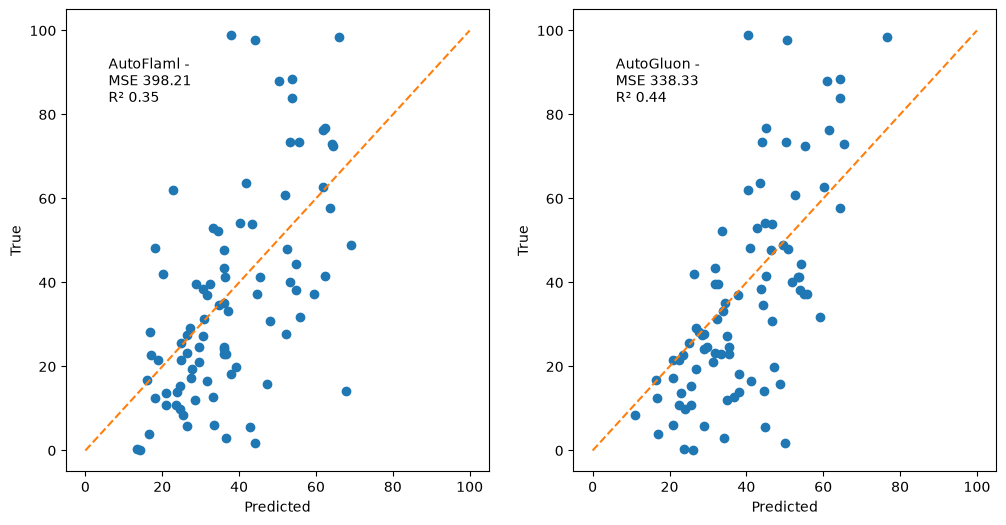

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))


# FLAML
y_pred = automl_flaml.predict(test_data.drop("tendency_to_crystallize", axis=1).values)

ax1.plot(y_pred, test_data["tendency_to_crystallize"], "o")
ax1.plot([0, 100], [0, 100], "--")
ax1.set_ylabel("True")
ax1.set_xlabel("Predicted")


mse_autoFlaml = mean_squared_error(
    test_data["tendency_to_crystallize"].values,
    y_pred,
)

r2_autoFlaml = r2_score(
    test_data["tendency_to_crystallize"].values,
    y_pred,
)

ax1.text(0.1, 0.8, f"AutoFlaml - \nMSE {mse_autoFlaml:.2f}\nR² {r2_autoFlaml:.2f}", transform=ax1.transAxes)


# AutoGluon

y_pred = predictor.predict(test_data.drop("tendency_to_crystallize", axis=1))
ax2.plot(y_pred, test_data["tendency_to_crystallize"], "o")
ax2.plot([0, 100], [0, 100], "--")
ax2.set_ylabel("True")
ax2.set_xlabel("Predicted")


mse_autoGluon = mean_squared_error(
    test_data["tendency_to_crystallize"].values,
    y_pred,
)

r2_autoGluon = r2_score(
    test_data["tendency_to_crystallize"].values,
    y_pred,
)

ax2.text(
    0.1,
    0.8,
    f"AutoGluon - \nMSE {mse_autoGluon:.2f}\nR² {r2_autoGluon:.2f}",
    transform=ax2.transAxes,
)

## Further Tasks

1. Performance: Analyze the MSE values and parity plots. Which AutoML framework performs better on the dataset?

2. Time budget: Modify the `time_budget` and `time_limit` parameters in FLAML and AutoGluon: try 30, 120, 300 seconds. Compare how training time affects model performance.

3. Iterations: Experiment with different `max_iter` values in FLAML to see how the number of model trials impacts results.

4. Presets: Experiment with different `presets` values in AutoGluon to see how they affect training time and results.

5. Baseline: Train a `DummyRegressor` (scikit-learn) that always predicts the mean of the training data. Compare its MSE and R² with FLAML and AutoGluon. How much better are the AutoML models really?

6. Predictions: Use your models to predict the tendency to crystallize of polymers that are not in the dataset, e.g., polystyrene `[*]CC([*])c1ccccc1` or PTFE `[*]C(F)(F)C([*])(F)F`. Use `PS(smiles).fingerprint()` to compute the fingerprints. Do the predictions make sense?

7. Worst predictions: Find the 5 test polymers with the largest prediction error and draw them with `PS(...)`. Do they have something in common? if you exectue `PS('*CC*')` in a notebook cell, it draws the polymer for you.

8. Random split: Change `random_state` in `train_test_split` (e.g., 0, 1, 2, 3, 4) and retrain. How much does the R² change? What does this tell you about the reliability of a single test score?

9. Data size: Retrain AutoGluon on 25%, 50%, 75%, and 100% of the training data and plot the test MSE against the training set size. Would more data help?

10. Metrics: Compute the mean absolute error (MAE). What does it mean in the units of the tendency to crystallize (range 0 to 100)?

11. Classification: Convert the problem into a classification task: tendency to crystallize > 50 → `"crystalline"`, otherwise `"amorphous"`. Train AutoGluon again and compute the accuracy.

